> **Superseded (2026-11-25).** Kept for the record of how the project developed. The current pipeline is `ev_siting_final.ipynb` (EV-registration demand weight, audit fixes, all models and scenarios in one notebook). Numbers here use the earlier population-based weight.

# EV Charging Optimizer (Delhi): Model 3, MCLP (Maximal Covering Location Problem)

Chooses **p = 104** station sites from a fixed list of candidates so that as much demand as possible lies
within **R = 2.1 km** (straight line) of an open station. Same demand layer, same station count and same
yardstick as the grid and K-means models.

**Pipeline**
1. Load demand (`data/delhi_demand_weights.gpkg`), candidate sites, grid and K-means results, existing chargers
2. Build coverage sets: which candidates are within R of each demand point
3. Solve the MCLP (integer program, HiGHS solver via `scipy.optimize.milp`)
4. Evaluate with the common metrics; equity by SC share
5. Sensitivity: radius 1.5 / 3 km, 2 km candidate grid
6. Robustness: Monte Carlo persistence (random lambda, theta, weight noise), as for K-means
7. Three-way comparison: grid vs K-means vs MCLP
8. Export in the common station format

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import csr_matrix, hstack, eye

import demand_weights_mc as dwmc

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

## 1. Config and data contract

| Input | Source | Used for |
|---|---|---|
| Demand points | `data/delhi_demand_weights.gpkg`, layer `demand_weights` | demand `weight`; MC recompute (`R`, `Dm_*`) |
| Candidate sites | `Final Data/model_inputs/candidates_v1.csv`, `grid_km == 3` (206 sites) | sites MCLP chooses from (M1, M2) |
| Grid baseline | same file, `grid_km == 3` and `grid_candidate_1pct` (104 sites) | sets p; comparison |
| K-means stations | `outputs/kmeans_v2/kmeans_A_k104_stations.csv` | comparison |
| Existing chargers | `Final Data/model_inputs/existing_chargers_v1.csv` | scoring only (Scenario A) |
| SC share | `ward_master_v2.csv` | equity metric |

**Settings (one rule each):**
* **p = 104**, the grid method's station count, the same for all three models (D1).
* **R = 2,100 m straight line**, the team setting: the worst-case distance to the centre of a 3 km grid cell
  (half the diagonal, 3 km / √2 ≈ 2.1 km), so a station per cell would cover the whole cell.
* **Candidates = the 206 centres of the 3 km grid cells** (team setting M1). The grid model can only use the
  104 of them that pass the 1% rule; MCLP may use any of the 206.

In [2]:
CFG = dict(
    demand_path="data/delhi_demand_weights.gpkg", demand_layer="demand_weights", weight_col="weight",
    gis_path="Final Data/delhi_ev_gis_v1.gpkg", study_layer="study_area",
    candidates_path="Final Data/model_inputs/candidates_v1.csv", cand_grid_km=3,
    kmeans_path="outputs/kmeans_v2/kmeans_A_k104_stations.csv",
    chargers_path="Final Data/model_inputs/existing_chargers_v1.csv",
    ward_csv="ward_master_v2.csv",
    crs="EPSG:32643",
    R_m=2100, tie_break_R_m=1000,
    R_list_m=[1000, 1500, 2100, 3000],
    sens_R_m=[1500, 3000], sens_grid_km=[2],
    mc_runs=50, mc_sigma=0.30, mc_lam_range=(0.3, 0.8), mc_dirichlet_conc=50.0, seed=42,
    robust_threshold=0.8,
    time_limit_s=600,
    out_dir="outputs/mclp_v1",
)
OUT = Path(CFG["out_dir"]); OUT.mkdir(parents=True, exist_ok=True)
CRS = CFG["crs"]

## 2. Data loading

In [3]:
def xy(g):
    return np.column_stack([g.geometry.x.to_numpy(), g.geometry.y.to_numpy()])


def pts(df):
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["x"], df["y"]), crs=CRS)


demand = gpd.read_file(CFG["demand_path"], layer=CFG["demand_layer"]).to_crs(CRS)
X, w = xy(demand), demand[CFG["weight_col"]].to_numpy(float)
pop = demand["pop_alloc"].to_numpy(float)
study = gpd.read_file(CFG["gis_path"], layer=CFG["study_layer"]).to_crs(CRS)

cand_all = pd.read_csv(CFG["candidates_path"])
cand = pts(cand_all[cand_all["grid_km"] == CFG["cand_grid_km"]].reset_index(drop=True))
grid = cand[cand["grid_candidate_1pct"] == True]
p = len(grid)

kmeans = pts(pd.read_csv(CFG["kmeans_path"]))
ch = pd.read_csv(CFG["chargers_path"]); ch = ch[ch["in_study_area"] == True]
existing_all = pts(ch); existing_4w = existing_all[existing_all["scenario_b_fixed"] == True]

sc = pd.read_csv(CFG["ward_csv"]).set_index("ward_no")["sc_share"]
demand["sc_share"] = demand["ward_no"].map(sc)
demand["sc_q"] = pd.qcut(demand["sc_share"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])

print(f"Demand points {len(demand)} | candidates {len(cand)} ({CFG['cand_grid_km']} km grid) | p = {p} | "
      f"K-means stations {len(kmeans)} | existing chargers {len(existing_all)} (4W {len(existing_4w)})")

Demand points 1570 | candidates 206 (3 km grid) | p = 104 | K-means stations 104 | existing chargers 1323 (4W 98)


## 3. The common yardstick (identical to the K-means notebook)

In [4]:
def nearest_dist(points_xy, sites_xy):
    return cKDTree(sites_xy).query(points_xy)[0]


def wquantile(v, ww, q):
    o = np.argsort(v); c = np.cumsum(ww[o]) / ww.sum()
    return float(v[o][np.searchsorted(c, q)])


def evaluate_layout(demand_xy, demand_w, site_xy, R_list, name="layout", pop_w=None):
    """Common yardstick for all three models (demand-weighted)."""
    d = nearest_dist(demand_xy, site_xy)
    row = {"layout": name, "stations": len(site_xy),
           "mean_dist_m": float(np.average(d, weights=demand_w)),
           "median_dist_m": wquantile(d, demand_w, 0.5),
           "p95_dist_m": wquantile(d, demand_w, 0.95),
           "max_dist_m": float(d.max())}
    for R in R_list:
        row[f"cov_{R}m_pct"] = 100 * demand_w[d <= R].sum() / demand_w.sum()
    if pop_w is not None:
        row["pop_cov_2100m_pct"] = 100 * pop_w[d <= 2100].sum() / pop_w.sum()
    return {k: (round(v, 1) if isinstance(v, float) else v) for k, v in row.items()}

## 4. The MCLP model

Decision variables: `x_j = 1` if candidate j is opened (binary); `y_i` = 1 if demand point i is covered.

```
maximise    Σ_i  w_i · y_i                      (demand covered)
subject to  y_i ≤ Σ_{j within R of i} x_j       (a point counts as covered only if an open site is within R)
            Σ_j x_j = p                         (exactly p stations)
            x_j ∈ {0, 1},  0 ≤ y_i ≤ 1
```

**Tie-break.** Once most demand is covered, many layouts reach the same coverage. A second solve keeps the
coverage at its maximum and, among those layouts, maximises demand within 1 km, so stations sit as close to
demand as possible instead of being picked arbitrarily.

In [5]:
def coverage_matrix(X, S, R):
    nb = cKDTree(S).query_ball_point(X, R)
    rows = np.repeat(np.arange(len(X)), [len(a) for a in nb])
    cols = np.concatenate([np.asarray(a, dtype=int) for a in nb]) if len(rows) else np.array([], int)
    return csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(X), len(S)))


def solve_mclp(w, A, p, A_tie=None, time_limit=600):
    """Max-coverage MCLP; optional second stage maximises coverage of A_tie at the optimal primary coverage."""
    n, J = A.shape
    sel = hstack([csr_matrix(np.ones((1, J))), csr_matrix((1, n))])
    cons = [LinearConstraint(hstack([-A, eye(n)]), -np.inf, 0), LinearConstraint(sel, p, p)]
    integ = np.r_[np.ones(J), np.zeros(n)]
    opts = dict(time_limit=time_limit)
    r1 = milp(c=np.r_[np.zeros(J), -w], constraints=cons, integrality=integ, bounds=Bounds(0, 1), options=opts)
    best, r = -r1.fun, r1
    if A_tie is not None:
        # variables now [x (J), y (n), z (n)]; z_i = covered within the tie-break radius
        Z = csr_matrix((n, n))
        cons2 = [LinearConstraint(hstack([-A, eye(n), Z]), -np.inf, 0),                 # y_i <= Σ_{j in R} x_j
                 LinearConstraint(hstack([-A_tie, Z, eye(n)]), -np.inf, 0),             # z_i <= Σ_{j in R_tie} x_j
                 LinearConstraint(hstack([sel, csr_matrix((1, n))]), p, p),             # Σ x_j = p
                 LinearConstraint(hstack([csr_matrix((1, J)), csr_matrix(w.reshape(1, -1)), csr_matrix((1, n))]),
                                  best * (1 - 1e-9), np.inf)]                           # keep max coverage
        integ2 = np.r_[integ, np.zeros(n)]
        r2 = milp(c=np.r_[np.zeros(J + n), -w], constraints=cons2, integrality=integ2, bounds=Bounds(0, 1), options=opts)
        if r2.status == 0:
            r = r2
    open_ = np.flatnonzero(np.round(r.x[:J]) == 1)
    return open_, dict(status=r1.status, message=r1.message, coverage=best, gap=getattr(r1, "mip_gap", np.nan))


A = coverage_matrix(X, xy(cand), CFG["R_m"])
A_tie = coverage_matrix(X, xy(cand), CFG["tie_break_R_m"])
no_cand = np.asarray(A.sum(1)).ravel() == 0
print(f"Demand points with no candidate within {CFG['R_m']} m: {no_cand.sum()} (weight {w[no_cand].sum():.2f}) "
      f"-> upper bound on coverage {100 * (1 - w[no_cand].sum() / w.sum()):.1f}%")

t0 = time.time()
open_idx, info = solve_mclp(w, A, p, A_tie, CFG["time_limit_s"])
mclp = cand.iloc[open_idx].copy()
print(f"Solved in {time.time()-t0:.1f}s | {info['message']} | stations {len(mclp)} | "
      f"demand covered within {CFG['R_m']} m: {100 * info['coverage'] / w.sum():.2f}%")

Demand points with no candidate within 2100 m: 1 (weight 0.00) -> upper bound on coverage 100.0%
Solved in 0.1s | Optimization terminated successfully. (HiGHS Status 7: Optimal) | stations 104 | demand covered within 2100 m: 94.39%


## 5. Evaluation (common metrics)

In [6]:
rows = [evaluate_layout(X, w, xy(mclp), CFG["R_list_m"], f"MCLP (p={p}, R={CFG['R_m']} m)", pop),
        evaluate_layout(X, w, xy(kmeans), CFG["R_list_m"], f"K-means (k={len(kmeans)})", pop),
        evaluate_layout(X, w, xy(grid), CFG["R_list_m"], "grid baseline (3 km, 1%)", pop),
        evaluate_layout(X, w, xy(existing_4w), CFG["R_list_m"], "existing: confirmed 4W", pop),
        evaluate_layout(X, w, xy(existing_all), CFG["R_list_m"], "existing: all chargers", pop)]
summary = pd.DataFrame(rows).set_index("layout")
summary

,stations,mean_dist_m,median_dist_m,p95_dist_m,max_dist_m,cov_1000m_pct,cov_1500m_pct,cov_2100m_pct,cov_3000m_pct,pop_cov_2100m_pct
layout,,,,,,,,,,
"MCLP (p=104, R=2100 m)",104,1255.6,1227.6,2103.6,8466.5,31.0,69.3,94.4,98.0,97.5
K-means (k=104),104,1145.1,1111.7,2075.4,5376.0,40.2,77.7,95.3,99.2,98.1
"grid baseline (3 km, 1%)",104,1456.8,1227.6,3018.7,9658.4,27.6,60.7,83.8,94.5,83.7
existing: confirmed 4W,98,2118.5,1554.0,6041.3,14033.2,29.1,48.7,64.8,78.6,68.9
existing: all chargers,1323,645.7,396.9,1972.3,10300.5,84.4,92.3,95.4,97.8,97.9


**Equity.** Population coverage within 2.1 km by quintile of the ward's Scheduled Caste share (Q1 = lowest share).

In [7]:
eq = {}
for name, sxy in [("MCLP", xy(mclp)), ("K-means", xy(kmeans)), ("grid baseline", xy(grid)), ("existing 4W", xy(existing_4w))]:
    d = nearest_dist(X, sxy)
    cov = pd.Series(pop * (d <= 2100)).groupby(demand["sc_q"], observed=True).sum() / \
          pd.Series(pop).groupby(demand["sc_q"], observed=True).sum()
    eq[name] = (100 * cov).round(1)
equity = pd.DataFrame(eq).T
equity.columns = [f"{c} pop cov 2100 m %" for c in equity.columns]
equity

,Q1 pop cov 2100 m %,Q2 pop cov 2100 m %,Q3 pop cov 2100 m %,Q4 pop cov 2100 m %,Q5 pop cov 2100 m %
MCLP,98.9,98.4,93.4,88.1,98.8
K-means,98.8,98.7,95.2,92.2,99.2
grid baseline,85.5,86.9,76.0,77.7,82.6
existing 4W,78.9,64.6,61.6,44.7,67.2


## 6. Sensitivity

Radius 1.5 km and 3 km on the 3 km candidates, and R = 2.1 km on the denser 2 km candidate grid (428 sites).
Each layout is solved for its own radius and then scored with the common yardstick (coverage at 2.1 km shown
for comparability). The 2 km grid solve is slower (a few minutes).

In [8]:
sens_rows, sens_layouts = [], {}
for R in CFG["sens_R_m"]:
    t0 = time.time()
    o, inf = solve_mclp(w, coverage_matrix(X, xy(cand), R), p, None, CFG["time_limit_s"])
    sens_layouts[f"3 km cands, R={R}"] = cand.iloc[o]
    sens_rows.append(dict(variant=f"3 km candidates, R = {R} m", stations=len(o),
                          cov_own_R_pct=100 * inf["coverage"] / w.sum(), solve_s=time.time() - t0))
for gk in CFG["sens_grid_km"]:
    c2 = pts(cand_all[cand_all["grid_km"] == gk].reset_index(drop=True))
    t0 = time.time()
    o, inf = solve_mclp(w, coverage_matrix(X, xy(c2), CFG["R_m"]), p, None, CFG["time_limit_s"])
    sens_layouts[f"{gk} km cands, R={CFG['R_m']}"] = c2.iloc[o]
    sens_rows.append(dict(variant=f"{gk} km candidates ({len(c2)}), R = {CFG['R_m']} m", stations=len(o),
                          cov_own_R_pct=100 * inf["coverage"] / w.sum(), solve_s=time.time() - t0))
sens = pd.DataFrame(sens_rows)
for i, (k_, lay) in enumerate(sens_layouts.items()):
    d = nearest_dist(X, xy(lay))
    sens.loc[i, "cov_2100m_pct"] = 100 * w[d <= 2100].sum() / w.sum()
    sens.loc[i, "mean_dist_m"] = np.average(d, weights=w)
sens.round(1)

,variant,stations,cov_own_R_pct,solve_s,cov_2100m_pct,mean_dist_m
0,"3 km candidates, R = 1500 m",104,72.4,0.0,92.8,1343.9
1,"3 km candidates, R = 3000 m",104,100.0,0.0,80.1,1547.8
2,"2 km candidates (428), R = 2100 m",104,95.7,157.1,95.7,1303.5


## 7. Robustness: Monte Carlo persistence

Same draws as the K-means notebook: λ ~ Uniform(0.3, 0.8), θ ~ Dirichlet around the team's values,
lognormal noise σ = 0.3. Each run re-solves the MCLP (with the tie-break). Because MCLP picks from fixed
candidates 3 km apart, "a station within 1 km" means **the same site is chosen again**, so persistence is
simply the share of runs in which each base site is open. ≥ 80% = robust. (MCLP has no random start, so the
K-means "seed only" control is not needed.)

In [9]:
rng = np.random.default_rng(CFG["seed"] + 1000)
chosen = np.zeros(len(cand)); mc_rows = []
t0 = time.time()
for i in range(CFG["mc_runs"]):
    wp, par = dwmc.mc_weights(demand, rng, sigma=CFG["mc_sigma"], lam_range=CFG["mc_lam_range"],
                              dirichlet_conc=CFG["mc_dirichlet_conc"])
    o, inf = solve_mclp(wp, A, p, A_tie, CFG["time_limit_s"])
    chosen[o] += 1
    d = nearest_dist(X, xy(cand.iloc[o]))
    mc_rows.append(dict(run=i, **par, cov_on_base_w_pct=100 * w[d <= CFG["R_m"]].sum() / w.sum(),
                        overlap_with_base=len(set(o) & set(open_idx))))
mc_runs = pd.DataFrame(mc_rows)
cand["mc_open_share"] = chosen / CFG["mc_runs"]
mclp["persistence"] = cand.loc[mclp.index, "mc_open_share"].to_numpy()
mclp["robust"] = mclp["persistence"] >= CFG["robust_threshold"]
print(f"{CFG['mc_runs']} runs in {time.time()-t0:.0f}s | median persistence {mclp['persistence'].median():.2f} | "
      f"robust sites {int(mclp['robust'].sum())}/{p} | sites shared with base layout: mean "
      f"{mc_runs['overlap_with_base'].mean():.0f}/{p} | coverage on base weights {mc_runs['cov_on_base_w_pct'].mean():.1f}% "
      f"(min {mc_runs['cov_on_base_w_pct'].min():.1f}%)")
print(f"Candidates never chosen: {(cand['mc_open_share'] == 0).sum()} | always chosen: {(cand['mc_open_share'] == 1).sum()}")

50 runs in 4s | median persistence 1.00 | robust sites 89/104 | sites shared with base layout: mean 98/104 | coverage on base weights 94.2% (min 93.7%)
Candidates never chosen: 72 | always chosen: 69


## 8. Three-way comparison

**Spatial agreement:** for each station of method A, the distance to the nearest station of method B, and the
share of A's stations that have a B station within 1 km / 2 km. MCLP and grid both pick from the same 3 km
candidates, so their exact-site overlap is also shown.

In [10]:
lay = {"grid": grid, "K-means": kmeans, "MCLP": mclp}
agree = []
for a, ga in lay.items():
    for b, gb in lay.items():
        if a == b:
            continue
        d = nearest_dist(xy(ga), xy(gb))
        agree.append(dict(from_=a, to=b, median_dist_m=np.median(d), within_1km_pct=100 * (d <= 1000).mean(),
                          within_2km_pct=100 * (d <= 2000).mean()))
agree = pd.DataFrame(agree).rename(columns={"from_": "from"})
same = len(set(mclp["cand_id"]) & set(grid["cand_id"]))
print(f"MCLP and grid choose the same candidate at {same} of {p} sites")
agree.round(1)

MCLP and grid choose the same candidate at 77 of 104 sites


,from,to,median_dist_m,within_1km_pct,within_2km_pct
0,grid,K-means,1365.6,26.0,88.5
1,grid,MCLP,0.0,74.0,76.0
2,K-means,grid,1394.7,26.0,77.9
3,K-means,MCLP,1193.8,36.5,89.4
4,MCLP,grid,0.0,74.0,74.0
5,MCLP,K-means,1193.8,36.5,89.4


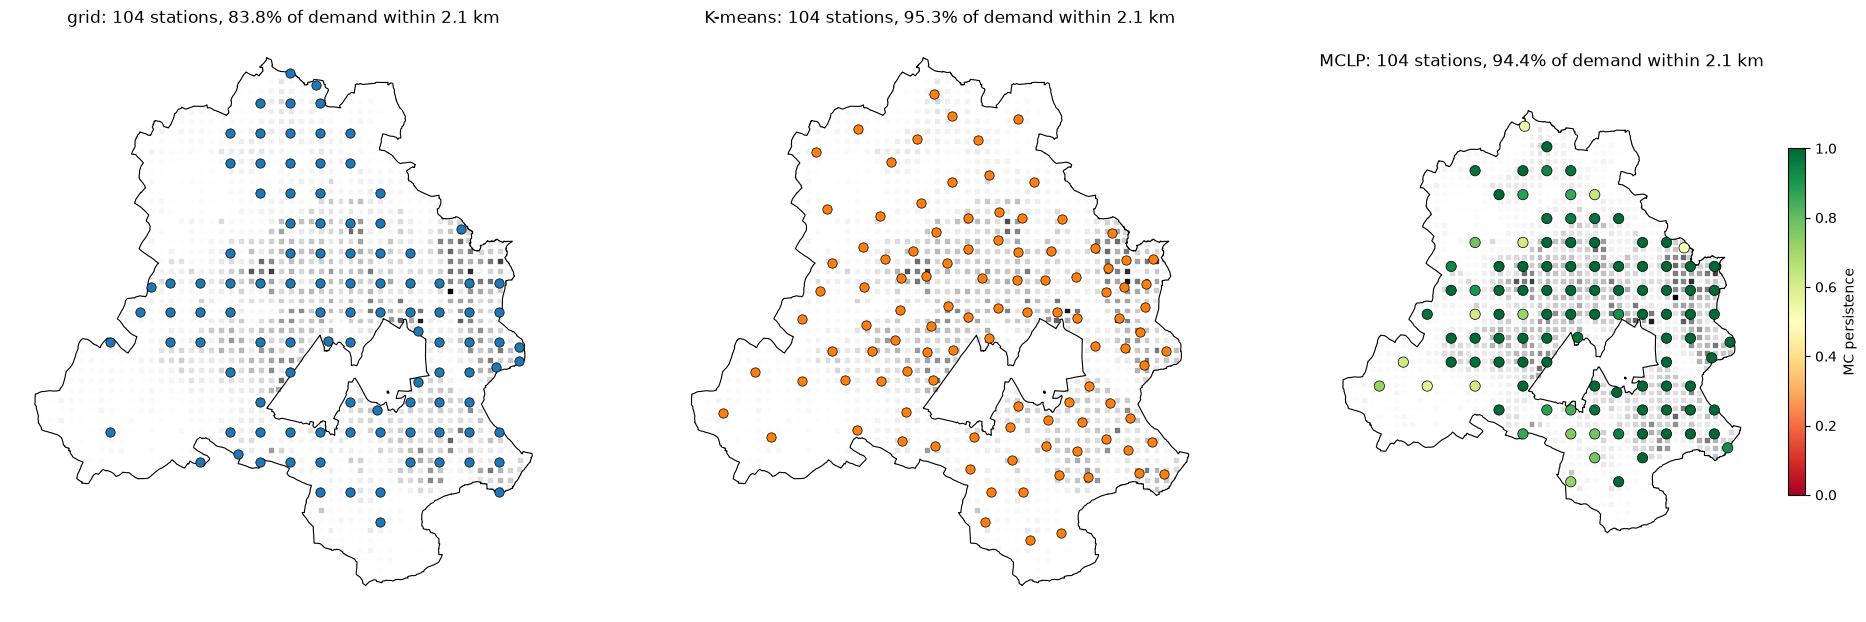

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(24, 9))
for ax, (name, g), col in zip(axes, lay.items(), ["tab:blue", "tab:orange", "tab:green"]):
    study.boundary.plot(ax=ax, color="black", lw=0.8)
    scp = ax.scatter(X[:, 0], X[:, 1], c=w, s=8, cmap="Greys", marker="s")
    if name == "MCLP":
        s_ = ax.scatter(g.geometry.x, g.geometry.y, c=g["persistence"], cmap="RdYlGn", vmin=0, vmax=1, s=55,
                        edgecolors="k", lw=0.5, zorder=5)
        plt.colorbar(s_, ax=ax, shrink=0.5, label="MC persistence")
    else:
        ax.scatter(g.geometry.x, g.geometry.y, s=45, color=col, edgecolors="k", lw=0.5, zorder=5)
    d = nearest_dist(X, xy(g))
    ax.set_title(f"{name}: {len(g)} stations, {100 * w[d <= 2100].sum() / w.sum():.1f}% of demand within 2.1 km")
    ax.set_aspect("equal"); ax.set_axis_off()
plt.savefig(OUT / "three_way_map.png", dpi=120, bbox_inches="tight"); plt.show()

## 9. Export

In [12]:
out = mclp.copy()
out.insert(0, "method", "mclp"); out.insert(1, "scenario", "A"); out.insert(2, "budget", p)
out["station_id"] = np.arange(len(out))
ll = out.to_crs("EPSG:4326"); out["lon"], out["lat"] = ll.geometry.x, ll.geometry.y
out["is_existing_fixed"] = False
cols = ["method", "scenario", "budget", "station_id", "x", "y", "lon", "lat", "cand_id", "is_existing_fixed",
        "grid_candidate_1pct", "share_ci", "persistence", "robust"]
tag = f"mclp_A_p{p}_R{CFG['R_m']}"
out[cols].to_csv(OUT / f"{tag}_stations.csv", index=False)
gpd.GeoDataFrame(out[cols], geometry=out.geometry, crs=CRS).to_crs("EPSG:4326").to_file(OUT / f"{tag}_stations.geojson", driver="GeoJSON")
gpkg = OUT / f"{tag}.gpkg"
if gpkg.exists():
    gpkg.unlink()                                     # this notebook owns this file; rebuilt each run
gpd.GeoDataFrame(out[cols], geometry=out.geometry, crs=CRS).to_file(gpkg, layer="mclp_stations", driver="GPKG")
cand[["cand_id", "grid_candidate_1pct", "mc_open_share", "geometry"]].to_file(gpkg, layer="mclp_candidates", driver="GPKG")

# combined overlay file: all three Scenario A layouts + demand, EPSG:32643
comb = Path("outputs") / f"siting_comparison_A_{p}.gpkg"
if comb.exists():
    comb.unlink()
keep = ["method", "station_id", "x", "y", "geometry"]
g_out = grid.assign(method="grid", station_id=np.arange(len(grid)))
for name, g in [("grid_stations", g_out[keep + ["cand_id", "share_ci"]]),
                ("kmeans_stations", kmeans.assign(method="kmeans")[keep + ["cluster_demand", "persistence"]]),
                ("mclp_stations", gpd.GeoDataFrame(out[cols], geometry=out.geometry, crs=CRS)[["method", "station_id", "x", "y", "cand_id", "persistence", "geometry"]])]:
    g.to_file(comb, layer=name, driver="GPKG")
gpd.read_file(CFG["demand_path"], layer="cells_polygons")[["cell_id", "weight", "R", "D", "geometry"]] \
    .to_file(comb, layer="demand_cells", driver="GPKG")
study.to_file(comb, layer="study_area", driver="GPKG")
print("GeoPackages:", gpkg, "|", comb)
summary.to_csv(OUT / "summary.csv"); equity.to_csv(OUT / "equity.csv"); sens.to_csv(OUT / "sensitivity.csv", index=False)
mc_runs.to_csv(OUT / "mc_runs.csv", index=False); agree.to_csv(OUT / "spatial_agreement.csv", index=False)
cand[["cand_id", "x", "y", "grid_candidate_1pct", "mc_open_share"]].to_csv(OUT / "candidate_mc_open_share.csv", index=False)
print("Saved to", OUT)

GeoPackages: outputs/mclp_v1/mclp_A_p104_R2100.gpkg | outputs/siting_comparison_A_104.gpkg
Saved to outputs/mclp_v1


## Assumptions and open items

* **p = 104** (grid method's count, D1); **R = 2.1 km** straight line; **candidates = 206 centres of the 3 km
  grid** (M1/M2). Radius 1.5 / 3 km and the 2 km candidate grid are sensitivity runs.
* Tie-break: among layouts with maximal 2.1 km coverage, the one with most demand within 1 km is chosen.
* Candidate spacing limits MCLP: sites are 3 km apart, so it cannot place a station exactly where demand
  peaks, while K-means can. The 2 km candidate run shows how much this costs.
* Straight-line distance. The precomputed road matrices go from ward centroids, not from the 1 km demand
  cells, so a road-distance MCLP on this demand layer needs new network distances (not done).
* Scenario B (149 confirmed 4W sites fixed open) not built yet.